In [1]:
import yfinance as yf
# from yahooquery import Ticker
import requests
import matplotlib.pyplot as plt
import numpy as np
import math
import pickle
from datetime import datetime

In [2]:
def time_elapsed(start_time, end_time):
    if not isinstance(start_time, datetime) or not isinstance(end_time, datetime):
        return None
    elapsed_time = end_time - start_time
    return elapsed_time.days  # Return the number of days

In [3]:
amd = yf.download('AMD', start='2009-01-01')

# ticker = yf.Ticker("AMD")
# amd = ticker.history(start='2009-01-01')

# ticker = Ticker("AMD")
# amd = ticker.history(start='2009-01-01')


[*********************100%***********************]  1 of 1 completed


In [4]:
display(amd)

Price,Close,High,Low,Open,Volume
Ticker,AMD,AMD,AMD,AMD,AMD
Date,,,,,
2009-01-02,2.380000,2.430000,2.170000,2.190000,13832100
2009-01-05,2.670000,2.680000,2.350000,2.370000,19326900
2009-01-06,2.780000,2.850000,2.550000,2.750000,23860000
2009-01-07,2.660000,2.720000,2.550000,2.720000,14026300
2009-01-08,2.740000,2.740000,2.510000,2.640000,13413000
...,...,...,...,...,...
2026-10-05,631.750000,633.500000,619.989990,630.609985,13717500
2026-10-06,649.419983,658.520020,628.000000,648.039978,24245900


In [5]:
close_prices = amd[('Close', 'AMD')]

In [6]:
display(close_prices)

Date
2009-01-02      2.380000
2009-01-05      2.670000
2009-01-06      2.780000
2009-01-07      2.660000
2009-01-08      2.740000
                 ...    
2026-10-05    631.750000
2026-10-06    649.419983
2026-10-07    645.859985
2026-10-08    620.679993
2026-10-09    608.099976
Name: (Close, AMD), Length: 4470, dtype: float64

In [7]:
# Total growth = last price / first price
total_growth = close_prices.iloc[-1] / close_prices.iloc[0]

In [8]:
print(total_growth)

255.50417913689273


In [9]:
# Current price / first record (e.g., price at the beginning of 2009)
# provides us with the total growth %
# total_growth = amd['Adj Close'][-1] / amd['Adj Close'][0]
# total_growth = amd['adjclose'][-1] / amd['adjclose'][0]
# total_growth = amd['Close'][-1] / amd['Close'][0]


# Next, we want to annualize this percentage
# First, we convert our time elapsed to the number of years elapsed
number_of_days = time_elapsed(amd.index[0], amd.index[-1])
number_of_years = number_of_days / 365.0  # Assuming 365 days per year

In [10]:
print(number_of_days)
print(number_of_years)

6489
17.778082191780822


In [11]:
print(amd.index[0])
print(amd.index[-1])

2009-01-02 00:00:00
2026-10-09 00:00:00


In [12]:


# Second, we can raise the total growth to the inverse of the number of years
# (e.g., ~1/10 at the time of writing) to annualize our growth rate
cagr = (total_growth ** (1/number_of_years)) - 1

# Now that we have the mean annual growth rate above,
# we'll also need to calculate the standard deviation of the
# daily price changes
std_dev = amd[('Close', 'AMD')].pct_change().std()

# Next, because there are roughly ~252 trading days in a year,
# we'll need to scale this by an annualization factor
number_of_trading_days = 252
std_dev = std_dev * math.sqrt(number_of_trading_days)

# Calculate daily return percentages for 1 year's worth of trading (252 days)
daily_return_percentages = np.random.normal(cagr / number_of_trading_days, std_dev / math.sqrt(number_of_trading_days), number_of_trading_days) + 1

# Now that we have created a random series of future daily return percentages,
# we can apply these forward-looking to our last stock price in the window,
# effectively carrying forward a price prediction for the next year

# This distribution is known as a 'random walk'
price_series = [amd[('Close', 'AMD')][-1]]

for j in daily_return_percentages:
    price_series.append(price_series[-1] * j)


C:\Users\prana\AppData\Local\Temp\ipykernel_1272\1753085843.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  price_series = [amd[('Close', 'AMD')][-1]]


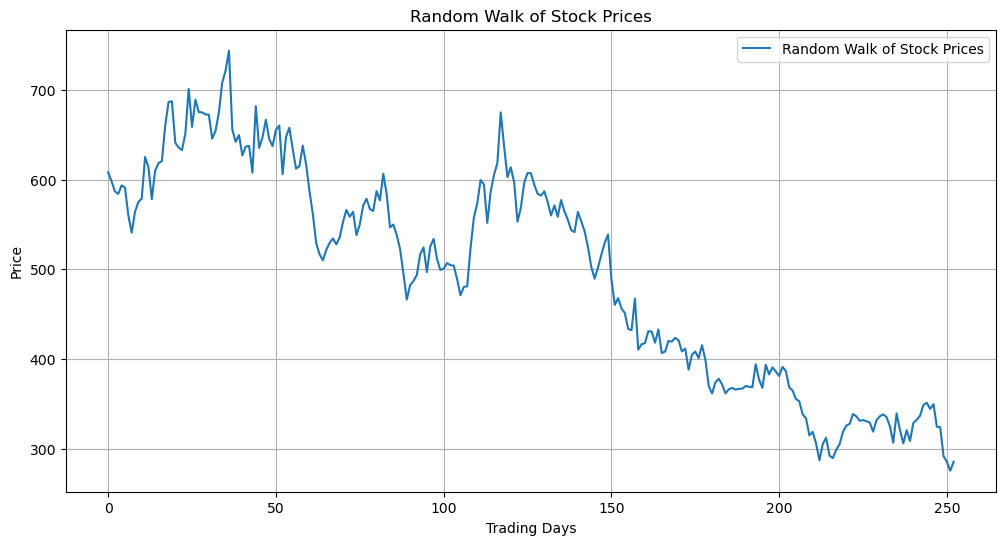

In [13]:
# Plot a single 'random walk' of stock prices
plt.figure(figsize=(12, 6))
plt.plot(price_series, label='Random Walk of Stock Prices')
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walk of Stock Prices')
plt.legend()
plt.grid(True)
plt.show()

# Now that we've created a single random walk above,
# we can simulate this process over a large sample size to
# get a better sense of the true expected distribution
number_of_trials = 3000

# Set up an additional array to collect all possible
# closing prices on the last day of the window.
# We can use this for a histogram to get a clearer sense of possible outcomes
closing_prices = []


C:\Users\prana\AppData\Local\Temp\ipykernel_1272\3249896996.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  price_series = [amd[('Close', 'AMD')][-1]]


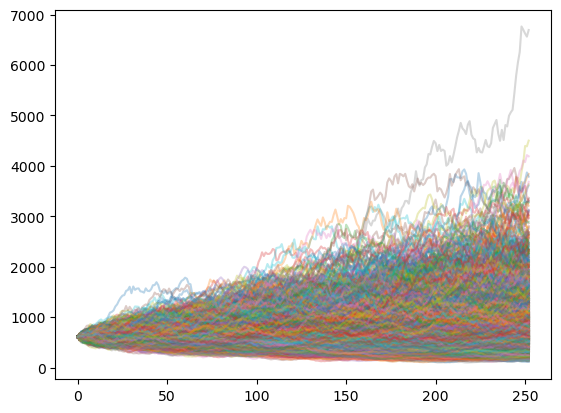

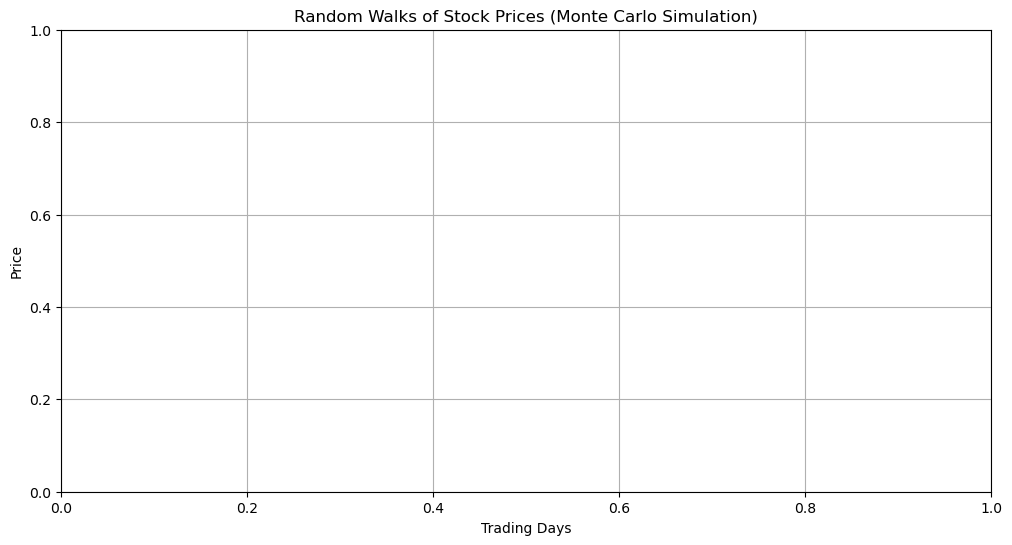

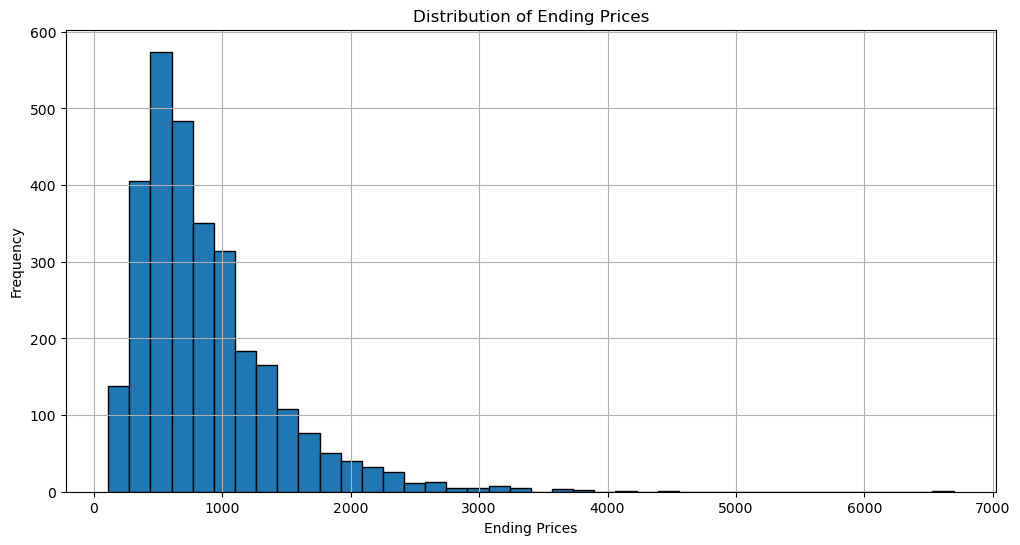

Expected price:  874.02


C:\Users\prana\AppData\Local\Temp\ipykernel_1272\3249896996.py:50: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.axvline(amd[('Close', 'AMD')][-1], color='g', linestyle='dashed', linewidth=2, label='Current Price')


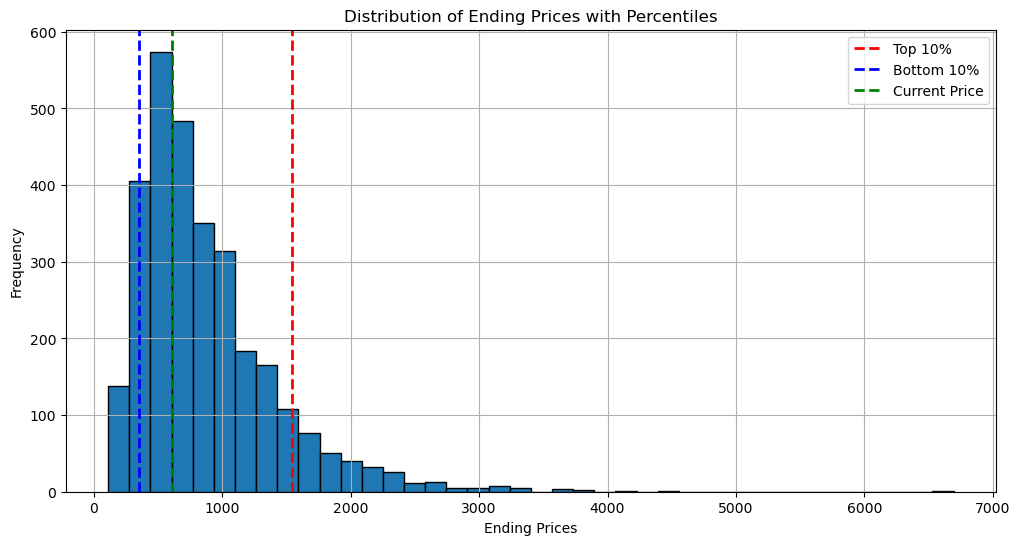

In [14]:
for i in range(number_of_trials):
    # Calculate randomized return percentages following our normal distribution
    # and using the mean / std dev we calculated above
    daily_return_percentages = np.random.normal(cagr / number_of_trading_days, std_dev / math.sqrt(number_of_trading_days), number_of_trading_days) + 1
    price_series = [amd[('Close', 'AMD')][-1]]

    for j in daily_return_percentages:
        # Extrapolate the price out for the next year
        price_series.append(price_series[-1] * j)

    # Append closing prices on the last day of the window for the histogram
    closing_prices.append(price_series[-1])

    # Plot all random walks
    plt.plot(price_series, alpha=0.3)

plt.figure(figsize=(12, 6))
plt.xlabel('Trading Days')
plt.ylabel('Price')
plt.title('Random Walks of Stock Prices (Monte Carlo Simulation)')
plt.grid(True)
plt.show()

# Plot histogram
plt.figure(figsize=(12, 6))
plt.hist(closing_prices, bins=40, edgecolor='black')
plt.xlabel('Ending Prices')
plt.ylabel('Frequency')
plt.title('Distribution of Ending Prices')
plt.grid(True)
plt.show()

# Calculate the mean of all ending prices, allowing us to arrive at the most probable ending point
mean_end_price = round(np.mean(closing_prices), 2)
print("Expected price: ", str(mean_end_price))

# Lastly, split the distribution into percentiles to help gauge risk vs. reward

# Pull the top 10% of possible outcomes
top_ten = np.percentile(closing_prices, 100 - 10)

# Pull the bottom 10% of possible outcomes
bottom_ten = np.percentile(closing_prices, 10)

# Create the histogram again
plt.figure(figsize=(12, 6))
plt.hist(closing_prices, bins=40, edgecolor='black')
plt.axvline(top_ten, color='r', linestyle='dashed', linewidth=2, label='Top 10%')
plt.axvline(bottom_ten, color='b', linestyle='dashed', linewidth=2, label='Bottom 10%')
plt.axvline(amd[('Close', 'AMD')][-1], color='g', linestyle='dashed', linewidth=2, label='Current Price')
plt.xlabel('Ending Prices')
plt.ylabel('Frequency')
plt.title('Distribution of Ending Prices with Percentiles')
plt.legend()
plt.grid(True)
plt.savefig('histogram.png')
plt.show()

In [15]:
# Store the data in a pickle file
data_to_pickle = {
    #'apple_data': apple,
    'closing_prices': closing_prices,
    'mean_end_price': mean_end_price,
    'top_ten_percentile': top_ten,
    'bottom_ten_percentile': bottom_ten,
}

pickle_file_path = 'stock_simulation_data_amd.pkl'

with open(pickle_file_path, 'wb') as pickle_file:
    pickle.dump(data_to_pickle, pickle_file)

print(f'Data has been saved to {pickle_file_path}')


Data has been saved to stock_simulation_data_amd.pkl


In [17]:
import pandas as pd
target_date = amd.index[-1] + pd.tseries.offsets.BDay(252)
print("Last data date:", amd.index[-1].date())
print("Expected price is for approx.:", target_date.date())
print("Expected price:", mean_end_price)

Last data date: 2026-10-09
Expected price is for approx.: 2027-09-28
Expected price: 874.02
